# 01 — Simulation and state
Explore the fixed-minus Ising model with $h=\lambda/N$. The production `IsingModel` defines the measure; `Simulator` defines the transition rule. Run cells in order. State-changing examples construct a fresh simulator before advancing it.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from ising import IsingModel, Simulator
import ising.kernels as kernels
import ising.observables as obs
from ising.state import make_state
import inspect

In [10]:
spin_cmap = ListedColormap(["#14263a", "#2c4a6b", "#e3952f"])
def show_state(spins, ax=None, title=""):
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 4))
    image = spins.copy().astype(int)
    image[0, :] = image[-1, :] = -2
    image[:, 0] = image[:, -1] = -2
    ax.imshow(image, cmap=spin_cmap, vmin=-2, vmax=1, interpolation="nearest")
    ax.set(title=title, xticks=[], yticks=[])
    return ax

## Parameters and initialization
Change these parameters and rerun the following cells. The Python backend is easiest to inspect; Numba is useful for longer experiments.

In [3]:
N, beta, lam, seed = 24, 0.55, 3.0, 42
model = IsingModel(N=N, beta=beta, lam=lam)
print(model, "physical field:", model.h)
print(inspect.getsource(make_state))

IsingModel(N=24, beta=0.55, lam=3.0) physical field: 0.125
def make_state(N, init, rng):
    spins = -np.ones((N + 2, N + 2), dtype=np.int8)
    if init == "plus":
        spins[1:-1, 1:-1] = 1
    elif init == "random":
        spins[1:-1, 1:-1] = rng.choice([-1, 1], size=(N, N)).astype(np.int8)
    elif init != "minus":
        raise ValueError(init)
    return spins



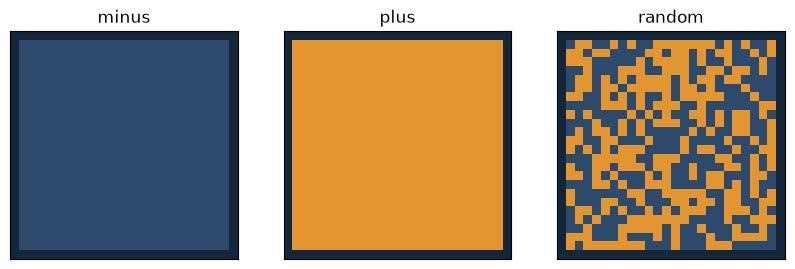

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for init, ax in zip(("minus", "plus", "random"), axes):
    spins = make_state(N, init, np.random.default_rng(seed))
    assert spins.shape == (N+2, N+2)
    assert np.all(spins[[0,-1], :] == -1) and np.all(spins[:, [0,-1]] == -1)
    show_state(spins, ax, init)
plt.show()

## Views, copies and safe state replacement
`state` is a read-only live view, not a historical snapshot. Use `.copy()` for snapshots and `set_state` to refresh cached statistics. `set_state` does not reset the clock or RNG.

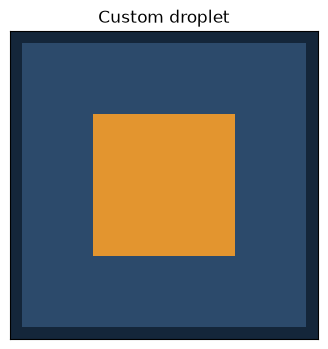

In [5]:
sim = Simulator(model, init="minus", seed=seed, backend="python")
view = sim.state
snapshot = view.copy()
custom_state = snapshot.copy()
custom_state[1+N//4:1+3*N//4, 1+N//4:1+3*N//4] = 1
sim.set_state(custom_state)
assert np.array_equal(view, custom_state)
assert not view.flags.writeable
assert np.all(snapshot == -1)
assert np.isclose(sim.magnetization, obs.magnetization(custom_state))
show_state(sim.state, title="Custom droplet"); plt.show()

## Clock and single attempts
Local sweeps consist of $N^2$ attempts with replacement. Cluster sweeps consist of one full cluster update. The two time units are not physically equivalent.

In [6]:
sim = Simulator(model, seed=seed, backend="python")
sim.advance_updates(1)
print(sim.updates, sim.t)
assert sim.t == 1/N**2
sim.advance(1)
assert sim.updates == N**2+1
print(sim.observe(clusters=False))

1 0.001736111111111111
{'sweep': 1.0017361111111112, 'updates': 577, 'magnetization': -0.9652777777777778, 'plus_fraction': 0.017361111111111105, 'interface_length': 38, 'interaction_energy': -1124, 'field_energy': 69.5, 'energy': -1054.5, 'excess_energy': 73.5}


## Compare all four dynamics
These are single seeded trajectories, not statistical estimates or a comparison of physical time. Change the initial state or field and repeat.

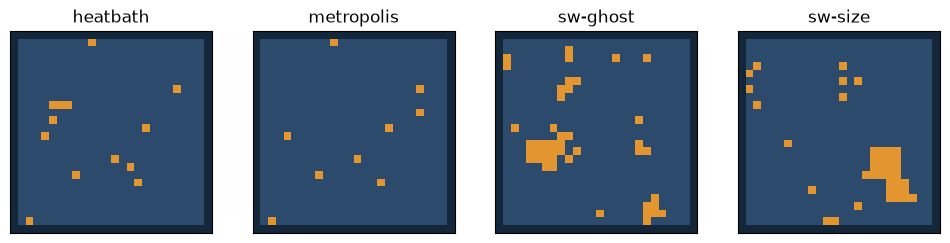

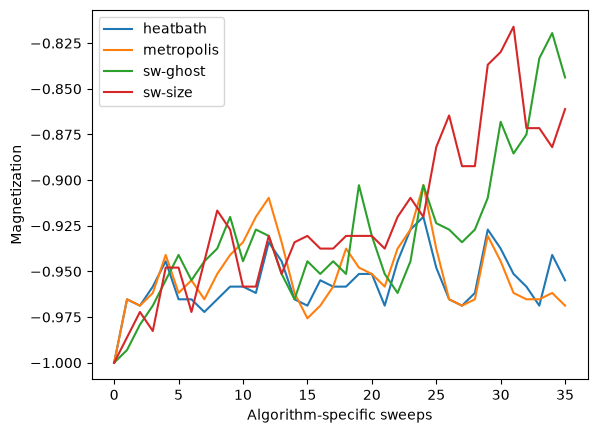

In [7]:
num_sweeps = 35
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
fig2, ax2 = plt.subplots()
for dynamics, ax in zip(("heatbath", "metropolis", "sw-ghost", "sw-size"), axes):
    sim = Simulator(model, init="minus", seed=seed, dynamics=dynamics, backend="python")
    magnetization_history = [sim.magnetization]
    for _ in range(num_sweeps):
        sim.advance()
        magnetization_history.append(sim.magnetization)
    show_state(sim.state, ax, dynamics)
    ax2.plot(range(num_sweeps+1), magnetization_history, label=dynamics)
    assert sim.t == num_sweeps
ax2.set(xlabel="Algorithm-specific sweeps", ylabel="Magnetization")
ax2.legend(); plt.show()

## Source inspection
Use `Simulator.advance?` in a new interactive cell for help, or inspect the implementation below.

In [8]:
print(inspect.getsource(Simulator._advance))

    def _advance(self, count, direction=0, threshold=0.0):
        if direction and direction*self.magnetization >= direction*threshold:
            return True
        if self._cluster_kernel is None:
            return self._advance_local(count, direction, threshold)
        return self._advance_cluster(count, direction, threshold)

